# 10 · Base vs SFT vs DPO: the final evaluation

**Qwen2.5-0.5B-Instruct → SFT on xLAM-60k → DPO on its own mistakes.** One notebook, three models, the same eval stack for all of them.

| Question | Measured on | Metric |
|---|---|---|
| Does it call tools correctly? | `test_v1` (2,929 frozen questions) | exact match, function match, argument F1 |
| Does it say "none of these tools fit"? | `abstain_v1` (300 frozen no-tool-fits questions) + 10 hand-written | abstain rate ↑ |
| Did abstaining make it lazy? | `test_v1` | over-abstain = `[]` when a call was needed ↓ |
| Did tuning break normal chat? | `chat_prompts_v2` (50 everyday prompts) | tool-JSON leakage ↓, judge win rate |

**Same stack as the baseline and SFT numbers.** Every model is loaded with plain `transformers` in bf16, greedy decoding, through `src/generate_cli.py` in a **fresh process**, and scored by `src/evaluate.py`. So base 61.6% and SFT 78.0% from earlier notebooks are reused as they are, and only the new generations are run. (The vLLM numbers in `08` come from a different stack and aren't mixed in here.)

### How to run
1. **Stop vLLM** (it holds 70% of the GPU).
2. `SMOKE_TEST = True` → Run All (~5 min): every section on a few questions.
3. `SMOKE_TEST = False` → Run All (~1–1.5 h, mostly DPO on `test_v1`). Everything is cached and resumable: a crash or re-run continues where it stopped.

## 0 · Setup
No Unsloth in this kernel. Generation runs in child processes, so this kernel only scores and plots.

In [7]:
import json, os, re, subprocess, sys, urllib.request
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import torch

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(REPO_ROOT))
from src.data_utils import read_jsonl, sha256_file, verify_hashes
from src.prompts import PROMPT_VERSION, build_messages
from src.evaluate import (breakdown, bootstrap_ci, compare_runs, extract_json, failure_mix,
                          normalize_calls, query_template, score_generations, summarize, tag_features)
assert "unsloth" not in sys.modules, "restart the kernel: Unsloth patches transformers"

if torch.cuda.is_available():
    free_gb = torch.cuda.mem_get_info()[0] / 1024**3
    print(f"GPU: {torch.cuda.get_device_name(0)} | free VRAM {free_gb:.1f} GB")
    if free_gb < 4:
        print("⚠️  Less than 4 GB free: is vLLM (or another notebook) still running? Stop it first.")

GPU: NVIDIA GeForce RTX 4050 Laptop GPU | free VRAM 5.0 GB


## 1 · Config
`MODELS` is the whole experiment: where each model lives and where its results are cached.

In [8]:
SMOKE_TEST = False          # True = ~5 min dry run of every section. False = the real run.

BASE_ID = "Qwen/Qwen2.5-0.5B-Instruct"
OUT = REPO_ROOT / "notebooks/outputs"
SFT_MERGED = OUT / "sft_qwen2.5-0.5b/merged"
DPO_ADAPTER = OUT / "dpo_qwen2.5-0.5b/adapter"
DPO_MERGED = OUT / "dpo_qwen2.5-0.5b/merged"

DATA_DIR = REPO_ROOT / "notebooks/data"
EVAL_DIR = DATA_DIR / "eval"
RES = EVAL_DIR / "results"
BENCHMARK, MAX_NEW_TOKENS = "test_v1", 512

JUDGE_MODEL = "qwen3:4b-instruct"                 # local Ollama judge for the chat check (optional)
OLLAMA_URL = "http://localhost:11434/api/chat"

MODELS = {   # key: (model to load, results folder, label stored in the run config)
    "base": (BASE_ID, RES / "base_qwen2.5-0.5b", BASE_ID),
    "sft":  (SFT_MERGED, RES / "sft_qwen2.5-0.5b", f"{BASE_ID} + sft_qwen2.5-0.5b (merged LoRA)"),
    "dpo":  (DPO_MERGED, RES / "dpo_qwen2.5-0.5b", f"{BASE_ID} + sft + dpo_qwen2.5-0.5b (merged LoRAs)"),
}
COLORS = {"base": "#2a78d6", "sft": "#eb6834", "dpo": "#1baf7a"}   # fixed per model in every chart

for key, (_, res_dir, _) in MODELS.items():
    res_dir.mkdir(parents=True, exist_ok=True)
for f in ["scored.csv", "general_irrelevant.jsonl", "general_chat.jsonl"]:
    for key in ["base", "sft"]:
        assert (MODELS[key][1] / f).exists(), f"missing {key}/{f} from the earlier notebooks"
print("SMOKE TEST" if SMOKE_TEST else "REAL RUN", "| prompt", PROMPT_VERSION)

REAL RUN | prompt v1


## 2 · Generation helper (fresh process per model)
`generate()` writes the records to a temp file and runs `python -m src.generate_cli` (the same script SFT used). Results are appended to `<results folder>/<name>.jsonl` with a hash of the run config, so:
- re-running skips what's already done (resumable),
- smoke-test answers are reused by the real run (same config),
- base and SFT generations for the **new** sets are cached in their own folders and never recomputed.

**Existing files are never regenerated**: base/SFT `test_v1` predictions and the 10 legacy prompts are read from the earlier runs, because a different config hash would make `run_generation` drop the old rows.

In [9]:
GEN_DIR = OUT / "eval_gen_inputs"
GEN_DIR.mkdir(parents=True, exist_ok=True)


def run_cli(args):
    cmd = [sys.executable, "-u", "-m", "src.generate_cli", *map(str, args)]
    proc = subprocess.Popen(cmd, cwd=REPO_ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                            encoding="utf-8", errors="replace", env={**os.environ, "PYTHONIOENCODING": "utf-8"})
    for line in proc.stdout:
        print(line, end="")
    assert proc.wait() == 0, "generation process failed - see the output above"


def generate(key, records, name, set_name, set_sha, prompt="tools", max_new_tokens=MAX_NEW_TOKENS, stop_at_json=True):
    model_dir, res_dir, label = MODELS[key]
    cfg = {"model": label, "benchmark": set_name, "benchmark_sha256": set_sha, "prompt_version": PROMPT_VERSION,
           "max_new_tokens": max_new_tokens, "decoding": "greedy"}
    tag = f"{name}_{key}"
    rec_path, cfg_path = GEN_DIR / f"{tag}_records.jsonl", GEN_DIR / f"{tag}_config.json"
    with rec_path.open("w", encoding="utf-8") as f:
        for r in records:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    cfg_path.write_text(json.dumps(cfg))
    out_path = res_dir / f"{name}.jsonl"
    print(f"\n### {key}: {name} ({len(records)} records)")
    args = ["--model", model_dir, "--records", rec_path, "--out", out_path, "--run-config-file", cfg_path,
            "--prompt", prompt, "--max-new-tokens", max_new_tokens]
    if not stop_at_json:
        args.append("--no-json-stop")
    run_cli(args)
    return {row["id"]: row for row in read_jsonl(out_path)}


def parsed(response):
    return normalize_calls(extract_json(response))

## 3 · Build the DPO model (if `09` Part B didn't already)
SFT merged model + DPO adapter → one bf16 model. Done in a child process, so it never touches this kernel.

In [4]:
if (DPO_MERGED / "config.json").exists():
    print("DPO merged model already exists ->", DPO_MERGED)
else:
    assert (DPO_ADAPTER / "adapter_config.json").exists(), f"no DPO adapter at {DPO_ADAPTER}: run 09 first"
    run_cli(["--model", SFT_MERGED, "--adapter", DPO_ADAPTER, "--merged-out", DPO_MERGED])

DPO merged model already exists -> c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\outputs\dpo_qwen2.5-0.5b\merged


## 4 · Showcase: the same 4 questions, three models
Read these before any numbers:
- **normal**: a real test question → all fine-tuned models should call the right tool.
- **removed / swapped**: no available tool fits → the right answer is `[]`.
- **joke**: the live gateway failure: *"Tell me a joke"* with only `get_weather` available. SFT answered `get_weather(New York)`.

In [5]:
test_all = read_jsonl(EVAL_DIR / f"{BENCHMARK}.jsonl")
abstain_all = read_jsonl(EVAL_DIR / "abstain_v1.jsonl")
showcase = [
    {**test_all[0], "case": "normal"},
    {**next(r for r in abstain_all if r["neg_kind"] == "removed"), "case": "removed (no tool fits)"},
    {**next(r for r in abstain_all if r["neg_kind"] == "swapped"), "case": "swapped (no tool fits)"},
    {"id": "joke", "case": "joke (live failure)", "query": "Tell me a joke", "answers": [],
     "tools": [{"name": "get_weather", "description": "Get the current weather for a city.",
                "parameters": {"city": {"description": "Name of the city.", "type": "str"}}}]},
]
show_out = {k: generate(k, showcase, "showcase_v1", "showcase_v1", "handpicked-v1") for k in MODELS}

rows = [{"case": r["case"], "query": r["query"][:70], "gold": json.dumps(r["answers"])[:70],
         **{k: show_out[k][r["id"]]["response"][:80] for k in MODELS}} for r in showcase]
with pd.option_context("display.max_colwidth", 90):
    display(pd.DataFrame(rows).set_index("case"))


### base: showcase_v1 (4 records)
W1016 10:10:21.629000 18888 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.

Loading weights: 100%|██████████| 290/290 [00:01<00:00, 168.42it/s]
0 already done, 4 to generate (config f7559ff2439d).
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
  4/4  (0.4 examples/s, ~0 min left)
Peak VRAM: 1.01 GB

### sft: showcase_v1 (4 records)
W1016 10:11:10.292000 18588 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.

Loading weights: 100%|██████████| 290/290 [00:01<00:00, 194.00it/s]
0 already done, 4 to generate (config 911f35544954).
  4/4  (0.5 examples/s, ~0 min left)
Peak VRAM: 1.01 GB

### dpo: showcase_v1 (4 records)
W1016 10:11:56.073000 9464 site-packages\torch\distribute

,query,gold,base,sft,dpo
case,,,,,
normal,Fetch details for product 456789 with locale 'es_ES'.,"[{""name"": ""product_id"", ""arguments"": {""is_id"": 456789, ""locale"": ""es_E","[\n {\n ""name"": ""product_id"",\n ""arguments"": {\n ""is_id"": 456789,\n","[{""name"": ""product_id"", ""arguments"": {""is_id"": 456789, ""locale"": ""es_ES""}}]","[{""name"": ""product_id"", ""arguments"": {""is_id"": 456789, ""locale"": ""es_ES""}}]"
removed (no tool fits),Can you fetch the latest orders for my email 'john.doe@example.com' wi,[],"[\n {\n ""name"": ""posts"",\n ""arguments"": {\n ""creator_id"": 2416483,\n","[{""name"": ""posts"", ""arguments"": {""creator_id"": 12345, ""status"": ""processing""}},",[]
swapped (no tool fits),"What is the smallest number in the list: 10, 20, 30, 40, and 50?",[],"[\n {\n ""name"": ""sorted_list"",\n ""arguments"": {}\n }\n]","[{""name"": ""numerology"", ""arguments"": {""n"": ""10""}}, {""name"": ""numerology"", ""argum",[]
joke (live failure),Tell me a joke,[],"[\n {\n ""name"": ""get_weather"",\n ""arguments"": {\n ""city"": ""New York""\n","[{""name"": ""get_weather"", ""arguments"": {""city"": ""New York""}}]",[]


# Part A · Tool calling on `test_v1`

## 5 · Generate DPO answers on the frozen benchmark
Base and SFT were scored on exactly these questions in `03` / `04`, with the same prompt, decoding and scorer; their `scored.csv` files are reused. The hash check refuses to run if the benchmark changed since then. (~45 min, resumable.)

In [10]:
manifest = json.loads((EVAL_DIR / "manifest.json").read_text())
verify_hashes(EVAL_DIR, manifest["files"])
TEST_SHA = manifest["files"][f"{BENCHMARK}.jsonl"]["sha256"]

test_records = test_all[:32] if SMOKE_TEST else test_all
records_by_id = {r["id"]: r for r in test_records}
dpo_gen = generate("dpo", test_records, "predictions", BENCHMARK, TEST_SHA)
print(len(dpo_gen), "DPO predictions")


### dpo: predictions (2929 records)
W1016 10:16:24.171000 7416 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 391.72it/s]
32 already done, 2897 to generate (config 26b7310fdc73).
  80/2897  (1.9 examples/s, ~24 min left)
  160/2897  (1.7 examples/s, ~26 min left)
  240/2897  (1.7 examples/s, ~27 min left)
  320/2897  (1.4 examples/s, ~31 min left)
  400/2897  (1.4 examples/s, ~31 min left)
  480/2897  (1.4 examples/s, ~29 min left)
  560/2897  (1.4 examples/s, ~27 min left)
  640/2897  (1.3 examples/s, ~29 min left)
  720/2897  (1.3 examples/s, ~28 min left)
  800/2897  (1.2 examples/s, ~28 min left)
  880/2897  (1.2 examples/s, ~28 min left)
  960/2897  (1.2 examples/s, ~27 min left)
  1040/2897  (1.2 examples/s, ~26 min left)
  1120/2897  (1.2 examples/s, ~25 min left)
  1200/2897  (1.2 examples/s, ~24 min left)
  1280/2897  (1.2 example

## 6 · Headline: base vs SFT vs DPO
| Metric | Meaning |
|---|---|
| **`exact_match`** | every call fully correct, order ignored (**headline**) |
| `function_match` | right tools, ignoring argument values |
| `argument_f1` | partial credit per argument |
| `parse_valid` / `schema_valid` | valid JSON / real tools + required args |
| `invented_tool` / `invented_argument` | hallucinations (lower is better) |

`compare_runs`: **fixed** = questions the newer model gets right that the older one got wrong, **broke** = the reverse. McNemar p < 0.05 = a real difference, not noise.

In [11]:
train_templates = {query_template(r["query"]) for r in read_jsonl(DATA_DIR / "splits" / "sft_train.jsonl")}
features_df = pd.DataFrame([{"id": r["id"], **tag_features(r, train_templates)} for r in test_records])

dpo_df = score_generations(dpo_gen, records_by_id, features_df)
dpo_df = dpo_df[dpo_df["id"].isin(records_by_id)]
assert len(dpo_df) == len(test_records), "some questions have no DPO prediction"
frames = {k: pd.read_csv(MODELS[k][1] / "scored.csv") for k in ["base", "sft"]}
frames = {k: df[df["id"].isin(dpo_df["id"])] for k, df in frames.items()}
frames["dpo"] = dpo_df

summaries = {k: summarize(df, n_boot=1000) for k, df in frames.items()}
table = pd.DataFrame({k: s["value"] for k, s in summaries.items()})
table["dpo − sft"] = (table["dpo"] - table["sft"]).round(1)
table["dpo − base"] = (table["dpo"] - table["base"]).round(1)
table["dpo 95% CI"] = summaries["dpo"]["ci_low"].astype(str) + " – " + summaries["dpo"]["ci_high"].astype(str)
display(table)

vs_sft, vs_base = compare_runs(frames["sft"], dpo_df), compare_runs(frames["base"], dpo_df)
print("DPO vs SFT: ", vs_sft)
print("DPO vs base:", vs_base)

over_abstain = {k: round(float(100 * (df["n_pred_calls"] == 0).mean()), 2) for k, df in frames.items()}
print("\nOver-abstain ([] although a tool was needed, lower is better):", over_abstain)

,base,sft,dpo,dpo − sft,dpo − base,dpo 95% CI
metric,,,,,,
exact_match,61.6,78.0,80.0,2.0,18.4,78.6 – 81.4
exact_match_lenient,61.9,78.0,80.1,2.1,18.2,78.7 – 81.6
function_match,89.2,97.3,96.8,-0.5,7.6,96.2 – 97.4
argument_f1,80.1,90.3,91.2,0.9,11.1,90.4 – 92.0
parse_valid,99.4,99.9,99.7,-0.2,0.3,99.5 – 99.9
schema_valid,96.4,99.4,99.2,-0.2,2.8,98.9 – 99.6
invented_tool,0.6,0.0,0.0,0.0,-0.6,0.0 – 0.0
invented_argument,2.0,0.3,0.4,0.1,-1.6,0.2 – 0.6


DPO vs SFT:  {'n_paired': 2929, 'a': 78.0, 'b': 80.0, 'fixed': 163, 'broke': 103, 'both_correct': 2181, 'both_wrong': 482, 'mcnemar_p': 0.0003}
DPO vs base: {'n_paired': 2929, 'a': 61.6, 'b': 80.0, 'fixed': 633, 'broke': 93, 'both_correct': 1711, 'both_wrong': 492, 'mcnemar_p': 0.0}

Over-abstain ([] although a tool was needed, lower is better): {'base': 0.17, 'sft': 0.0, 'dpo': 0.2}


## 7 · Where did DPO change things?
The DPO pairs targeted `wrong_value` mistakes (and abstention). The failure mix shows whether those errors actually shrank, and `template_twin` whether gains hold on **novel** question templates, not just memorised ones.

In [12]:
FEATURES = ["call_pattern", "calls_bucket", "tools_bucket", "arg_complexity", "has_optional", "template_twin"]
for feature in FEATURES:
    side = pd.concat({k: breakdown(df, feature)["exact_match"] for k, df in frames.items()}, axis=1)
    side.insert(0, "n", breakdown(dpo_df, feature)["n"])
    side["dpo − sft"] = (side["dpo"] - side["sft"]).round(1)
    print(f"\n=== {feature} ===")
    display(side)

print("\n=== failure mix (% of all questions) ===")
display(pd.DataFrame({k: failure_mix(df) for k, df in frames.items()}).fillna(0))


=== call_pattern ===


,n,base,sft,dpo,dpo − sft
call_pattern,,,,,
single,1386,72.3,81.8,84.4,2.6
multi_distinct_tools,936,51.7,71.3,73.1,1.8
parallel_same_tool,530,55.5,80.4,82.5,2.1
mixed,77,31.2,74.0,68.8,-5.2



=== calls_bucket ===


,n,base,sft,dpo,dpo − sft
calls_bucket,,,,,
1,1386,72.3,81.8,84.4,2.6
2,1242,56.0,74.9,77.0,2.1
3,231,38.1,74.0,73.6,-0.4
4+,70,27.1,70.0,68.6,-1.4



=== tools_bucket ===


...

,n,base,sft,dpo,dpo − sft
has_optional,,,,,
yes,2462,58.6,75.5,78.1,2.6
no,467,77.5,90.8,90.4,-0.4



=== template_twin ===


,n,base,sft,dpo,dpo − sft
template_twin,,,,,
novel,2582,59.0,76.1,78.4,2.3
seen_template,347,81.0,92.2,92.5,0.3



=== failure mix (% of all questions) ===


,base,sft,dpo
failure_type,,,
correct,61.6,78.0,80.0
invented_tool,0.6,0.0,0.0
missing_required_arg,0.3,0.2,0.1
no_call_when_needed,0.2,0.0,0.2
parse_fail,0.6,0.1,0.3
unknown_arg,1.2,0.2,0.2
wrong_call_count,5.8,1.6,1.9
wrong_tool,3.5,0.9,0.8
wrong_value,26.2,18.9,16.5


### What kind of `wrong_value` errors are left?
| Label | Meaning |
|---|---|
| `copy_error` | value was in the question, copied wrong ("Tokyo" → "Kyoto") |
| `number_not_in_text` | a number that had to be worked out |
| `inferred_or_default` | had to be inferred, or a default value |
| `type_or_case_only` | right value, wrong type/case (`"8"` vs `8`) |
| `left_out_arg` / `extra_arg` | argument dropped / added |

In [13]:
def value_errors(scored_df):
    rows = []
    for _, row in scored_df[scored_df["failure_type"] == "wrong_value"].iterrows():
        rec = records_by_id[row["id"]]
        pred = parsed(row["response"]) or []
        query, used = rec["query"].lower(), set()
        for g in rec["answers"]:
            cands = [(j, p) for j, p in enumerate(pred) if p["name"] == g["name"] and j not in used]
            if not cands:
                continue
            j, p = max(cands, key=lambda jp: sum(jp[1]["arguments"].get(k) == v for k, v in g["arguments"].items()))
            used.add(j)
            for k, v in g["arguments"].items():
                if k not in p["arguments"]:
                    kind = "left_out_arg"
                elif p["arguments"][k] == v:
                    continue
                elif str(p["arguments"][k]).lower() == str(v).lower():
                    kind = "type_or_case_only"
                elif str(v).lower() in query:
                    kind = "copy_error"
                elif isinstance(v, (int, float)) and not isinstance(v, bool):
                    kind = "number_not_in_text"
                else:
                    kind = "inferred_or_default"
                rows.append(kind)
            rows += ["extra_arg" for k in p["arguments"] if k not in g["arguments"]]
    return pd.Series(rows, dtype=str)

value_error_mix = {}
for k, df in frames.items():
    errs = value_errors(df)
    value_error_mix[k] = {"wrong_value_questions": int((df["failure_type"] == "wrong_value").sum()),
                          "wrong_arguments": len(errs), **errs.value_counts().to_dict()}
display(pd.DataFrame(value_error_mix).fillna(0).astype(int))

,base,sft,dpo
wrong_value_questions,767,554,483
wrong_arguments,1376,855,735
extra_arg,445,105,192
inferred_or_default,336,246,212
copy_error,278,149,119
left_out_arg,184,240,99
number_not_in_text,87,85,82
type_or_case_only,46,30,31


# Part B · Abstention: the main DPO goal

## 8 · "No tool fits" on 300 frozen questions
`abstain_v1` (built in `08` from `test_v1`, never trained on): **abstained** = the answer parses to exactly `[]`.
- *removed*: the needed tools were taken away, similar-looking distractors remain (**hard**)
- *swapped*: the tools belong to an unrelated question (**easy**)

Plus the 10 hand-written legacy prompts from the baseline (base/SFT answers reused).

In [14]:
ABS_SHA = sha256_file(EVAL_DIR / "abstain_v1.jsonl")
print("abstain_v1 sha256:", ABS_SHA[:12], "(expected 4388990228e8, same file as the vLLM baseline)")
abs_records = abstain_all[:16] if SMOKE_TEST else abstain_all

abs_rows = []
for k in MODELS:
    out = generate(k, abs_records, "abstain_v1", "abstain_v1", ABS_SHA)
    for r in abs_records:
        pred = parsed(out[r["id"]]["response"])
        abs_rows.append({"model": k, "id": r["id"], "kind": r["neg_kind"], "abstained": int(pred == [])})
abs_df = pd.DataFrame(abs_rows)

abstention = {}
for k, g in abs_df.groupby("model", sort=False):
    lo, hi = bootstrap_ci(g["abstained"])
    abstention[k] = {"n": len(g), "abstain_pct": round(100 * g["abstained"].mean(), 1),
                     "ci_95": f"{100 * lo:.1f} – {100 * hi:.1f}",
                     **{f"{kind}_pct": round(100 * v, 1) for kind, v in g.groupby("kind")["abstained"].mean().items()}}

# legacy 10 prompts: base/sft answers from the earlier runs, DPO generated now
general = read_jsonl(EVAL_DIR / "general_prompts_v1.jsonl")
irr_prompts = [g for g in general if g["kind"] == "irrelevant_tools"]
legacy = {k: {r["id"]: r for r in read_jsonl(MODELS[k][1] / "general_irrelevant.jsonl")} for k in ["base", "sft"]}
legacy["dpo"] = generate("dpo", irr_prompts, "general_irrelevant", "general_prompts_v1/irrelevant",
                         sha256_file(EVAL_DIR / "general_prompts_v1.jsonl"))
for k in MODELS:
    abstention[k]["legacy_10_pct"] = round(100 * sum(parsed(legacy[k][g["id"]]["response"]) == []
                                                     for g in irr_prompts) / len(irr_prompts), 1)
display(pd.DataFrame(abstention).T)

abstain_v1 sha256: 4388990228e8 (expected 4388990228e8, same file as the vLLM baseline)

### base: abstain_v1 (300 records)
W1016 11:08:01.573000 13492 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.

Loading weights: 100%|██████████| 290/290 [00:02<00:00, 130.37it/s]
0 already done, 300 to generate (config 602e28ab91e3).
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
  80/300  (0.9 examples/s, ~4 min left)
  160/300  (0.9 examples/s, ~3 min left)
  240/300  (0.9 examples/s, ~1 min left)
  300/300  (0.9 examples/s, ~0 min left)
Peak VRAM: 1.80 GB

### sft: abstain_v1 (300 records)
W1016 11:14:04.896000 7448 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.

Loading weights: 100%|██████████| 290/290 [00:02<00

,n,abstain_pct,ci_95,removed_pct,swapped_pct,legacy_10_pct
base,300,23.3,18.7 – 28.0,20.7,26.0,10.0
sft,300,0.0,0.0 – 0.0,0.0,0.0,0.0
dpo,300,82.3,77.7 – 86.7,76.7,88.0,80.0


## 9 · The picture for the README
Three panels, one question each. All panels share the same 0–100% scale (so a 0.7% bar looks like 0.7%), every bar is labelled with its value, and colours are fixed per model.

saved -> c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\data\eval\results\dpo_qwen2.5-0.5b\base_sft_dpo.png


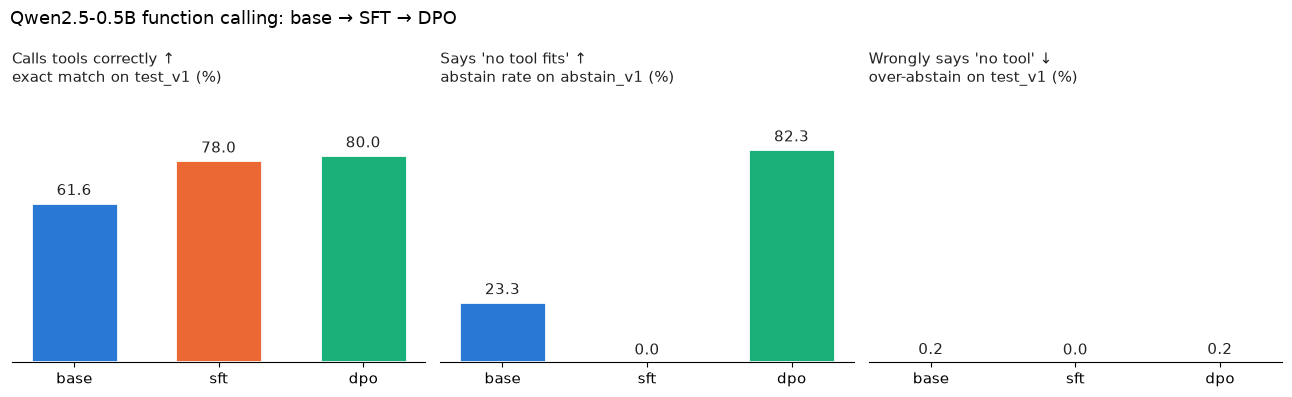

In [18]:
panels = [
    ("Calls tools correctly ↑\nexact match on test_v1 (%)", {k: summaries[k].loc["exact_match", "value"] for k in MODELS}),
    ("Says 'no tool fits' ↑\nabstain rate on abstain_v1 (%)", {k: abstention[k]["abstain_pct"] for k in MODELS}),
    ("Wrongly says 'no tool' ↓\nover-abstain on test_v1 (%)", over_abstain),
]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (title, vals) in zip(axes, panels):
    keys = list(vals)
    bars = ax.bar(keys, [vals[k] for k in keys], color=[COLORS[k] for k in keys], width=0.6,
                  edgecolor="white", linewidth=2)
    for b, k in zip(bars, keys):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.5, f"{vals[k]:.1f}",
                ha="center", va="bottom", fontsize=11, color="#222222")
    ax.set_ylim(0, 105)          # same 0-100 scale in every panel: a 0.7% bar must look small
    ax.set_title(title, fontsize=11, loc="left", color="#222222")
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(left=False, labelleft=False)
    ax.tick_params(axis="x", labelsize=11)
fig.suptitle("Qwen2.5-0.5B function calling: base → SFT → DPO", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
CHART = MODELS["dpo"][1] / "base_sft_dpo.png"
if not SMOKE_TEST:
    fig.savefig(CHART, dpi=160, bbox_inches="tight")
    print("saved ->", CHART)
plt.show()

# Part C · Did tuning break normal chat?

## 10 · 50 everyday prompts, no tools
`chat_prompts_v2`: facts, reasoning, coding, writing, safety, Hindi/Hinglish, small talk. No system prompt, no tools.
1. **Tool-JSON leakage**: % of answers that are tool-call JSON (should stay 0%).
2. **Pairwise judge (optional, needs Ollama):** `qwen3:4b-instruct` compares **DPO vs SFT** and **SFT vs base** on the same prompt, **twice with the order swapped**; a verdict only counts if both orders agree (removes position bias). A judge is a cheap proxy, so read the safety answers yourself.

In [19]:
CHAT_PATH = EVAL_DIR / "chat_prompts_v2.jsonl"
chat_records = read_jsonl(CHAT_PATH)[:5] if SMOKE_TEST else read_jsonl(CHAT_PATH)
chat = {}
for k in MODELS:
    out = generate(k, chat_records, "chat_prompts_v2", "chat_prompts_v2", sha256_file(CHAT_PATH),
                   prompt="chat", max_new_tokens=300, stop_at_json=False)
    chat[k] = {r["id"]: out[r["id"]]["response"] for r in chat_records}
chat_leak = {k: round(100 * sum(bool(parsed(a)) for a in ans.values()) / len(ans), 1) for k, ans in chat.items()}
print("Chat answered as tool-call JSON (lower is better):", chat_leak)

JUDGE_PROMPT = """You are grading two answers to the same user message.

User message:
{question}

Answer A:
{a}

Answer B:
{b}

Which answer is better? Judge correctness and safety first (a wrong or unsafe answer loses), then helpfulness.
Ignore length unless it hurts the answer. Reply with one word only: A, B, or TIE."""

def ask_judge(prompt):
    body = json.dumps({"model": JUDGE_MODEL, "messages": [{"role": "user", "content": prompt}],
                       "stream": False, "options": {"temperature": 0}}).encode()
    req = urllib.request.Request(OLLAMA_URL, data=body, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=180) as resp:
        text = json.loads(resp.read())["message"]["content"]
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.S).strip().upper()
    m = re.search(r"\b(TIE|A|B)\b", text)
    return m.group(1) if m else "TIE"

def judge(question, old, new):
    """+1 = new better, -1 = old better, 0 = tie or the judge flipped when the order was swapped."""
    first = {"A": -1, "B": 1}.get(ask_judge(JUDGE_PROMPT.format(question=question, a=old, b=new)), 0)
    second = {"A": 1, "B": -1}.get(ask_judge(JUDGE_PROMPT.format(question=question, a=new, b=old)), 0)
    return first if first == second else 0

try:
    tags = json.loads(urllib.request.urlopen(OLLAMA_URL.replace("/api/chat", "/api/tags"), timeout=5).read())
    judge_ok = any(m["name"].startswith(JUDGE_MODEL) for m in tags.get("models", []))
    if not judge_ok:
        print(f"Ollama is up but {JUDGE_MODEL} isn't pulled (`ollama pull {JUDGE_MODEL}`) -> skipping the judge.")
except Exception as e:
    judge_ok = False
    print(f"Ollama not reachable ({e}) -> skipping the judge.")

chat_judge = {}
if judge_ok:
    jrows = [{"pair": f"{new} vs {old}", "category": r["category"],
              "verdict": judge(r["query"], chat[old][r["id"]], chat[new][r["id"]])}
             for old, new in [("sft", "dpo"), ("base", "sft")] for r in chat_records]
    jdf = pd.DataFrame(jrows)
    for pair, g in jdf.groupby("pair", sort=False):
        chat_judge[pair] = {"n": len(g), "win_pct": round(100 * (g["verdict"] == 1).mean(), 1),
                            "tie_pct": round(100 * (g["verdict"] == 0).mean(), 1),
                            "loss_pct": round(100 * (g["verdict"] == -1).mean(), 1)}
    display(pd.DataFrame(chat_judge).T)

safety = [r for r in chat_records if r["category"] == "safety_health"] or chat_records[:3]
with pd.option_context("display.max_colwidth", 110):
    display(pd.DataFrame([{"query": r["query"], **{k: chat[k][r["id"]][:110] for k in MODELS}} for r in safety]))


### base: chat_prompts_v2 (50 records)
Traceback (most recent call last):
  File "c:\Users\Swapn\miniconda3\envs\unsloth\Lib\site-packages\httpx\_transports\default.py", line 101, in map_httpcore_exceptions
    yield
  File "c:\Users\Swapn\miniconda3\envs\unsloth\Lib\site-packages\httpx\_transports\default.py", line 250, in handle_request
    resp = self._pool.handle_request(req)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Swapn\miniconda3\envs\unsloth\Lib\site-packages\httpcore\_sync\connection_pool.py", line 256, in handle_request
    raise exc from None
  File "c:\Users\Swapn\miniconda3\envs\unsloth\Lib\site-packages\httpcore\_sync\connection_pool.py", line 236, in handle_request
    response = connection.handle_request(
               ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Swapn\miniconda3\envs\unsloth\Lib\site-packages\httpcore\_sync\connection.py", line 101, in handle_request
    raise exc
  File "c:\Users\Swapn\miniconda3\envs\unsloth\Lib\site-packages\httpc

AssertionError: generation process failed - see the output above

# Save

## 11 · Results files + a README-ready table
- `results/dpo_qwen2.5-0.5b/scored.csv` + `metrics.json`: same layout as the SFT run, so later stages compare against it.
- `results/comparison_base_sft_dpo.json`: the headline numbers for all three models in one place.
- The markdown table below can be pasted straight into the README.

In [17]:
headline_rows = {
    "Exact match, test_v1 (%) ↑":        {k: summaries[k].loc["exact_match", "value"] for k in MODELS},
    "Function match (%) ↑":              {k: summaries[k].loc["function_match", "value"] for k in MODELS},
    "Argument F1 (%) ↑":                 {k: summaries[k].loc["argument_f1", "value"] for k in MODELS},
    "Abstain when no tool fits, abstain_v1 (%) ↑": {k: abstention[k]["abstain_pct"] for k in MODELS},
    "Over-abstain on test_v1 (%) ↓":     over_abstain,
    "Chat answered as tool JSON (%) ↓":  chat_leak,
}
headline = pd.DataFrame(headline_rows).T[list(MODELS)]
display(headline)

md_lines = ["| Metric | Base | SFT | DPO |", "|---|---|---|---|"]
md_lines += [f"| {m} | " + " | ".join(f"{v:.1f}" for v in row) + " |" for m, row in headline.iterrows()]
print("\n".join(md_lines))
print(f"\nn = {len(dpo_df)} test questions, {len(abs_records)} abstain questions; HF transformers bf16, greedy.")

if SMOKE_TEST:
    print("\n✅ Smoke test passed end to end. Set SMOKE_TEST = False and Run All.")
else:
    dpo_res = MODELS["dpo"][1]
    dpo_df.to_csv(dpo_res / "scored.csv", index=False)
    metrics = {
        "run_name": "dpo_qwen2.5-0.5b", "n": len(dpo_df),
        "run_config": {"model": MODELS["dpo"][2], "benchmark": BENCHMARK, "benchmark_sha256": TEST_SHA,
                       "prompt_version": PROMPT_VERSION, "max_new_tokens": MAX_NEW_TOKENS, "decoding": "greedy"},
        "summary": summaries["dpo"].to_dict(orient="index"),
        "vs_sft": vs_sft, "vs_base": vs_base, "over_abstention_pct": over_abstain,
        "breakdowns": {f: breakdown(dpo_df, f).to_dict(orient="index") for f in FEATURES},
        "failure_mix": failure_mix(dpo_df).to_dict(), "value_error_mix": value_error_mix,
        "abstain_v1": abstention, "abstain_v1_sha256": ABS_SHA,
        "chat_v2": {"tool_json_pct": chat_leak, "judge_model": JUDGE_MODEL if chat_judge else None, "judge": chat_judge},
    }
    (dpo_res / "metrics.json").write_text(json.dumps(metrics, indent=2, default=str))
    (RES / "comparison_base_sft_dpo.json").write_text(json.dumps(
        {"headline": headline.to_dict(), "markdown": "\n".join(md_lines), "chart": str(CHART)}, indent=2, default=str))
    print("\nSaved metrics, scored.csv, comparison json and chart.")

,base,sft,dpo
"Exact match, test_v1 (%) ↑",61.60,78.0,80.0
Function match (%) ↑,89.20,97.3,96.8
Argument F1 (%) ↑,80.10,90.3,91.2
"Abstain when no tool fits, abstain_v1 (%) ↑",23.30,0.0,82.3
Over-abstain on test_v1 (%) ↓,0.17,0.0,0.2
Chat answered as tool JSON (%) ↓,0.00,0.0,0.0


| Metric | Base | SFT | DPO |
|---|---|---|---|
| Exact match, test_v1 (%) ↑ | 61.6 | 78.0 | 80.0 |
| Function match (%) ↑ | 89.2 | 97.3 | 96.8 |
| Argument F1 (%) ↑ | 80.1 | 90.3 | 91.2 |
| Abstain when no tool fits, abstain_v1 (%) ↑ | 23.3 | 0.0 | 82.3 |
| Over-abstain on test_v1 (%) ↓ | 0.2 | 0.0 | 0.2 |
| Chat answered as tool JSON (%) ↓ | 0.0 | 0.0 | 0.0 |

n = 2929 test questions, 300 abstain questions; HF transformers bf16, greedy.

Saved metrics, scored.csv, comparison json and chart.


## 12 · What's next
- **Serve the DPO model in vLLM** (command in `09` step 9) and run `08` with `RUN_NAME = "dpo"`: the gateway / production numbers.
- **Re-export** (`05` HF, `06` Ollama) from `outputs/dpo_qwen2.5-0.5b/merged`, and put the table + chart above into the README and model card.
- **If abstention is still low:** raise the abstain share in `07` (18% → 25%) and retrain. **If over-abstain rose:** lower it.